# Graph Neural Networks from Scratch — Tutorial 6: Graph Attention Networks (GAT)

### From equal neighbour aggregation to learning which neighbours matter

*📺 Video on YouTube | 🐍 Python · PyTorch · PyTorch Geometric | Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we implemented a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. We explored self-loops, degree matrices, graph normalization, and neighbourhood aggregation.

In Tutorial 3, we introduced **PyTorch** and transformed our GCN into a trainable neural network.

In Tutorial 4, we introduced **PyTorch Geometric (PyG)** and trained a GCN on the **Cora citation network**.

In Tutorial 5, we opened the GNN black box. We split a layer into **message, aggregate, and update**, implemented it with `index_add_`, rebuilt it with PyG's `MessagePassing`, and trained our own GraphSAGE-style layer on Cora.

At the end of Tutorial 5, we noticed something: our mean aggregation gives every neighbour the **same** weight, and GCN gives weights fixed by node **degree**. Neither looks at what the neighbours actually contain.

Imagine a paper that cites several others. Some are on the same topic; others are only loosely related. Should they all contribute equally? A better layer would **learn** how much to listen to each neighbour.

This is the idea behind **Graph Attention Networks (GATs)**. In this tutorial, we will build attention step by step, implement a GAT layer from scratch, rewrite it as a PyG `MessagePassing` layer, check it against PyG's `GATConv`, and train a GAT on Cora using the same workflow as Tutorials 4 and 5.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | ✅ |
| **6** | **Graph Attention Networks (GAT)** | **learned attention, neighbour weighting, multi-head attention** | **📍 You are here** |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of graph attention:

- Why equal or degree-based neighbour weighting can be limiting.
- How a node computes an attention score for each neighbour.
- How a **destination-wise softmax** turns scores into attention coefficients.
- Implementing a single-head GAT layer from scratch with plain PyTorch.
- Multi-head attention: concatenating vs. averaging heads.
- Writing GAT as a PyG `MessagePassing` layer and verifying it against `GATConv`.
- Training a GAT on Cora with the Tutorial 4–5 workflow.
- Inspecting attention weights, and why they must be interpreted carefully.

We will begin with the four-node graph from Tutorial 5, so every number can be checked by hand. Then, we will scale the same idea up to Cora.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
          Node Features
                |
                v
     Linear Projection  z = W h
                |
                v
   Attention Score per Edge  e_ij
                |
                v
     Destination-wise Softmax  α_ij
                |
                v
   Weighted Aggregation  Σ α_ij z_j
                |
                v
       Multi-Head Attention
                |
                v
    PyG MessagePassing → GATConv
                |
                v
     Cora: Train → Validate → Test
                |
                v
    Inspect Attention + Predictions
```

In the language of Tutorial 5, GAT changes only **one** thing: the **message** is now weighted by a learned coefficient $\alpha_{ij}$. Aggregation is still a sum, and the training loop stays the same.

> **New to attention?** Don't worry. Attention here is just a small learned function that outputs one number per edge, followed by a softmax. We will compute it by hand on a tiny graph first. Familiarity with `edge_index`, `index_add_`, and `MessagePassing` from Tutorial 5 will be helpful.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to what attention *does not* do. It weights messages by features, not by geometry. On a mesh, neighbouring cells already have physically meaningful weights (face areas, distances). Learned attention is not automatically a flux or interpolation weight.

**Let's teach our graph network not only to listen to its neighbours, but also to learn how much attention to give each one.**

## 1. Why graph attention?

Every layer we have used so far has the form:

$$
\mathbf h_i'=\sigma\left(\sum_{j\in\mathcal N(i)\cup\{i\}} c_{ij}\,\mathbf W\mathbf h_j\right)
$$

The only difference between them is how the coefficient $c_{ij}$ is chosen:

| Layer | Coefficient $c_{ij}$ | Depends on |
|---|---|---|
| Mean aggregation (Tutorial 5) | $\dfrac{1}{\lvert\mathcal N(i)\rvert}$ | number of neighbours |
| GCN (Tutorials 2–4) | $\dfrac{1}{\sqrt{\hat d_i\hat d_j}}$ | node degrees |
| **GAT (this tutorial)** | $\alpha_{ij}$ — **learned** | **node features** |

In GCN and mean aggregation, $c_{ij}$ is fixed before training. In GAT, $\alpha_{ij}$ is computed from the features of nodes $i$ and $j$ by a small trainable function.

**Important:** attention does not change which nodes are connected. The graph decides **who** can send messages; attention decides **how much** each message counts.

## 2. Setup

We use the same environment as Tutorials 4 and 5. If PyG is missing, the cell below installs it.

In [1]:
import sys
import subprocess

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

print("PyG:", torch_geometric.__version__)

torch.manual_seed(7)

PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1


# Part I — The attention mechanism

## 3. Four steps of a GAT layer

For a message from source node $j$ to destination node $i$:

**Step 1 — Project the features**

$$
\mathbf z_i=\mathbf W\mathbf h_i
$$

$\mathbf W$ is a trainable matrix, exactly as in GCN.

**Step 2 — Score each edge**

$$
e_{ij}=\operatorname{LeakyReLU}\left(\mathbf a^{T}\left[\mathbf z_i\ \Vert\ \mathbf z_j\right]\right)
$$

$\mathbf a$ is a trainable **attention vector**. It reads the destination and the source together and outputs one number: how compatible they are.

**Step 3 — Normalise over the destination's neighbourhood**

$$
\alpha_{ij}=\frac{\exp(e_{ij})}{\sum_{k\in\mathcal N(i)\cup\{i\}}\exp(e_{ik})}
$$

For every destination node, the incoming coefficients sum to one: $\sum_j\alpha_{ij}=1$.

**Step 4 — Aggregate weighted messages**

$$
\mathbf h_i'=\sigma\left(\sum_{j\in\mathcal N(i)\cup\{i\}}\alpha_{ij}\,\mathbf z_j\right)
$$

As in GCN, a **self-loop** is added, so a node also attends to itself.

| Symbol | Meaning | Trainable? |
|---|---|---|
| $\mathbf W$ | feature projection | ✅ |
| $\mathbf a$ | attention vector | ✅ |
| $e_{ij}$ | raw attention score of edge $j\rightarrow i$ | — |
| $\alpha_{ij}$ | normalised attention coefficient | — |

## 4. A useful trick: splitting the attention vector

Split $\mathbf a$ into two halves, $\mathbf a=[\mathbf a_{\text{dst}}\ \Vert\ \mathbf a_{\text{src}}]$. Then:

$$
\mathbf a^{T}[\mathbf z_i\Vert\mathbf z_j]=\underbrace{\mathbf a_{\text{dst}}^{T}\mathbf z_i}_{\text{one number per node}}+\underbrace{\mathbf a_{\text{src}}^{T}\mathbf z_j}_{\text{one number per node}}
$$

So we compute **two scores per node** once, and each edge score is just a sum of two lookups. We never build the concatenated vector for every edge. PyG's `GATConv` uses exactly this trick.

## 5. A tiny numerical example

Suppose a destination node receives three raw scores: $e_{i1}=0$, $e_{i2}=1$, $e_{i3}=2$. Softmax turns them into weights that sum to one.

In [2]:
scores = torch.tensor([0.0, 1.0, 2.0])

# Numerically stable softmax: subtract the maximum before exponentiating
exp_scores = (scores - scores.max()).exp()
attention = exp_scores / exp_scores.sum()

print("Scores:                ", scores.tolist())
print("Attention coefficients:", [round(a, 4) for a in attention.tolist()])
print("Sum:                   ", attention.sum().item())

Scores:                 [0.0, 1.0, 2.0]
Attention coefficients: [0.09, 0.2447, 0.6652]
Sum:                    1.0


The largest score gets the largest weight. These coefficients are **relative**: they compare neighbours of the same destination node only.

## 🧪 Hands-on Exercise 1

1. Set all three scores equal. What attention coefficients do you get? Which layer from Tutorial 5 does this reproduce?
2. Multiply all scores by 10. What happens to the distribution?
3. Add the same constant (e.g. +5) to all scores. Do the coefficients change? Why?

In [3]:
# TODO: experiment with different scores.

# scores = torch.tensor([1.0, 1.0, 1.0])
# scores = torch.tensor([0.0, 1.0, 2.0]) * 10
# scores = torch.tensor([0.0, 1.0, 2.0]) + 5
# print(torch.softmax(scores, dim=0))

# Part II — Attention on a small graph

## 6. Our example graph

We reuse the four-node graph from Tutorial 5:

```text
    0 ------ 1
     \      /
      \    /
        2 ------ 3
```

As before, a column `[j, i]` in `edge_index` means a message travels **from `j` to `i`**. Self-loops are added inside the GAT layer, so we do not store them here.

In [3]:
# Undirected edges: 0--1, 0--2, 1--2, 2--3
edge_index = torch.tensor([
    [0, 1, 0, 2, 1, 2, 2, 3],  # source nodes (j)
    [1, 0, 2, 0, 2, 1, 3, 2]   # destination nodes (i)
], dtype=torch.long)

x = torch.tensor([
    [1.0, 0.0],   # node 0
    [0.0, 1.0],   # node 1
    [1.0, 1.0],   # node 2
    [2.0, 0.0]    # node 3
])
num_nodes = x.size(0)

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)

Node features: torch.Size([4, 2])
Edge index: torch.Size([2, 8])


## 7. Destination-wise softmax

An ordinary softmax normalises **all** entries together. In graph attention, each destination node has its **own** group of incoming edges, and we need a separate softmax per group:

```text
edge scores        dst      softmax groups
  e(1→0)  ───────▶  0  ─┐
  e(2→0)  ───────▶  0  ─┴─ softmax over node 0's incoming edges
  e(0→1)  ───────▶  1  ─┐
  e(2→1)  ───────▶  1  ─┴─ softmax over node 1's incoming edges
  e(0→2)  ───────▶  2  ─┐
  e(1→2)  ───────▶  2   ├─ softmax over node 2's incoming edges
  e(3→2)  ───────▶  2  ─┘
  e(2→3)  ───────▶  3  ─── softmax over node 3's incoming edges
```

We build it from the same tools as Tutorial 5:

1. `scatter_reduce_(..., reduce="amax")` — maximum score per destination (for numerical stability).
2. `exp()` of the shifted scores.
3. `index_add_` — sum of exponentials per destination.
4. Divide each edge by its destination's sum.

In [4]:
def destination_softmax(scores, destination, num_nodes):
    """Softmax edge scores separately for each destination node.

    scores:      [num_edges, num_heads]
    destination: [num_edges]
    returns:     [num_edges, num_heads]
    """
    num_heads = scores.size(1)
    index = destination[:, None].expand(-1, num_heads)

    # 1. Maximum score per destination
    max_per_dst = scores.new_full((num_nodes, num_heads), -torch.inf)
    max_per_dst.scatter_reduce_(0, index, scores, reduce="amax", include_self=True)

    # 2. Shifted exponentials
    exp_scores = (scores - max_per_dst[destination]).exp()

    # 3. Sum of exponentials per destination
    denominator = scores.new_zeros((num_nodes, num_heads))
    denominator.index_add_(0, destination, exp_scores)

    # 4. Normalise
    return exp_scores / denominator[destination].clamp_min(1e-16)

Let's test it on random scores for our graph and check that each destination's coefficients sum to one.

In [5]:
demo_scores = torch.randn(edge_index.size(1), 1)
demo_alpha = destination_softmax(demo_scores, edge_index[1], num_nodes)

src, dst = edge_index
for node in range(num_nodes):
    incoming = dst == node
    print(
        f"Node {node}: sources={src[incoming].tolist()}, "
        f"alpha={[round(a, 3) for a in demo_alpha[incoming, 0].tolist()]}, "
        f"sum={demo_alpha[incoming].sum().item():.4f}"
    )

Node 0: sources=[1, 2], alpha=[0.87, 0.13], sum=1.0000
Node 1: sources=[0, 2], alpha=[0.679, 0.321], sum=1.0000
Node 2: sources=[0, 1, 3], alpha=[0.225, 0.474, 0.3], sum=1.0000
Node 3: sources=[2], alpha=[1.0], sum=1.0000


Node 3 has a single neighbour, so its only coefficient is exactly 1. Attention can only redistribute weight **among** neighbours; it cannot change how many there are.

## 🧪 Hands-on Exercise 2

PyG provides the same operation as `torch_geometric.utils.softmax(scores, index)`. Compare it with `destination_softmax` on `demo_scores` and print the maximum absolute difference.

In [7]:
# TODO: compare with PyG's grouped softmax.

# from torch_geometric.utils import softmax as pyg_softmax
# pyg_alpha = pyg_softmax(demo_scores, edge_index[1], num_nodes=num_nodes)
# print((pyg_alpha - demo_alpha).abs().max().item())

# Part III — A GAT layer from scratch

## 8. Single-head GAT layer

We now combine the four steps into a trainable layer. To support multiple heads later, all tensors carry a `heads` dimension from the start: `[nodes, heads, features]`.

| Step | Code |
|---|---|
| Add self-loops | `torch.cat([edge_index, loops], dim=1)` |
| 1. Project | `z = self.lin(x)` |
| 2. Score | `score_src[src] + score_dst[dst]` → LeakyReLU |
| 3. Normalise | `destination_softmax(...)` |
| 4. Aggregate | `index_add_` of `alpha * z[src]` |

In [6]:
class GATLayer(nn.Module):
    """GAT layer written with plain PyTorch."""

    def __init__(self, in_channels, out_channels, heads=1, concat=True,
                 negative_slope=0.2, dropout=0.0):
        super().__init__()
        self.out_channels = out_channels
        self.heads = heads
        self.concat = concat
        self.negative_slope = negative_slope
        self.dropout = dropout

        self.lin = nn.Linear(in_channels, heads * out_channels, bias=False)       # W
        self.att_src = nn.Parameter(torch.empty(1, heads, out_channels))          # a_src
        self.att_dst = nn.Parameter(torch.empty(1, heads, out_channels))          # a_dst
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))

        nn.init.xavier_uniform_(self.lin.weight)
        nn.init.xavier_uniform_(self.att_src)
        nn.init.xavier_uniform_(self.att_dst)

    def forward(self, x, edge_index, return_attention=False):
        N, H, C = x.size(0), self.heads, self.out_channels

        # Add self-loops: every node also attends to itself
        loops = torch.arange(N, device=x.device).repeat(2, 1)
        edge_index = torch.cat([edge_index, loops], dim=1)
        src, dst = edge_index

        # Step 1: project            -> [N, H, C]
        z = self.lin(x).view(N, H, C)

        # Step 2: score each edge    -> [E, H]
        score_src = (z * self.att_src).sum(dim=-1)   # [N, H]
        score_dst = (z * self.att_dst).sum(dim=-1)   # [N, H]
        e = F.leaky_relu(score_src[src] + score_dst[dst], self.negative_slope)

        # Step 3: normalise per destination
        alpha = destination_softmax(e, dst, N)
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        # Step 4: aggregate weighted messages
        out = z.new_zeros(N, H, C)
        out.index_add_(0, dst, alpha.unsqueeze(-1) * z[src])

        out = out.reshape(N, H * C) if self.concat else out.mean(dim=1)
        out = out + self.bias

        return (out, (edge_index, alpha)) if return_attention else out

gat = GATLayer(in_channels=2, out_channels=4, heads=1)
out = gat(x, edge_index)

print(gat)
print("Input shape:", x.shape)
print("Output shape:", out.shape)
print(out)

GATLayer(
  (lin): Linear(in_features=2, out_features=4, bias=False)
)
Input shape: torch.Size([4, 2])
Output shape: torch.Size([4, 4])
tensor([[ 0.1506,  0.7061, -0.1246,  0.7287],
        [ 0.1456,  0.7692, -0.0334,  0.7828],
        [ 0.1216,  1.0547,  0.3858,  1.0267],
        [ 0.1483,  1.2944,  0.4783,  1.2595]], grad_fn=<AddBackward0>)


## 9. Inspect the attention coefficients

We switch to evaluation mode (no dropout) and ask the layer to return its coefficients. Notice that each node now also appears as its own source, because of the self-loop.

In [7]:
gat.eval()
with torch.no_grad():
    _, (edges_with_loops, alpha) = gat(x, edge_index, return_attention=True)

src, dst = edges_with_loops
for node in range(num_nodes):
    incoming = dst == node
    print(
        f"Node {node}: sources={src[incoming].tolist()}, "
        f"alpha={[round(a, 3) for a in alpha[incoming, 0].tolist()]}, "
        f"sum={alpha[incoming, 0].sum().item():.4f}"
    )

Node 0: sources=[1, 2, 0], alpha=[0.29, 0.358, 0.352], sum=1.0000
Node 1: sources=[0, 2, 1], alpha=[0.401, 0.409, 0.19], sum=1.0000
Node 2: sources=[0, 1, 3, 2], alpha=[0.2, 0.168, 0.432, 0.201], sum=1.0000
Node 3: sources=[2, 3], alpha=[0.447, 0.553], sum=1.0000


The layer is untrained, so these weights are essentially random. During training, $\mathbf W$ and $\mathbf a$ are updated by backpropagation, and the coefficients change with them.

## 10. Count the learnable parameters

For one head with input size $F$ and output size $C$:

$$
\underbrace{F\cdot C}_{\mathbf W}+\underbrace{C}_{\mathbf a_{\text{src}}}+\underbrace{C}_{\mathbf a_{\text{dst}}}+\underbrace{C}_{\text{bias}}=2\cdot 4+4+4+4=20
$$

Compared with a GCN layer ($F\cdot C+C=12$), attention adds only $2C$ parameters per head.

In [8]:
for name, p in gat.named_parameters():
    print(f"{name:10s} {tuple(p.shape)}")
print("Learnable parameters:", sum(p.numel() for p in gat.parameters()))

att_src    (1, 1, 4)
att_dst    (1, 1, 4)
bias       (4,)
lin.weight (4, 2)
Learnable parameters: 20


## 11. Multi-head attention

A single head learns one way of weighting neighbours. With $K$ heads, the layer learns $K$ independent sets of $(\mathbf W^{(k)},\mathbf a^{(k)})$ in parallel, like several "opinions" about which neighbours matter.

The head outputs are then combined:

- **Hidden layers — concatenate:** $\ \mathbf h_i'=\big\Vert_{k=1}^{K}\ \sigma\Big(\sum_j\alpha_{ij}^{(k)}\mathbf W^{(k)}\mathbf h_j\Big)$
- **Output layer — average:** $\ \mathbf h_i'=\dfrac{1}{K}\sum_{k=1}^{K}\sum_j\alpha_{ij}^{(k)}\mathbf W^{(k)}\mathbf h_j$

```text
                 ┌── head 1 ──▶ [C] ─┐
  h_i  [F]  ─────┼── head 2 ──▶ [C] ─┼──▶ concat: [K·C]   or   mean: [C]
                 └── head 3 ──▶ [C] ─┘
```

In [11]:
multi_concat = GATLayer(2, 4, heads=3, concat=True)
multi_mean = GATLayer(2, 4, heads=3, concat=False)

print("3 heads, concatenated:", tuple(multi_concat(x, edge_index).shape))
print("3 heads, averaged:    ", tuple(multi_mean(x, edge_index).shape))

3 heads, concatenated: (4, 12)
3 heads, averaged:     (4, 4)


With three heads and four features per head, concatenation gives 12 features per node; averaging gives 4. The output layer averages so that it returns exactly one logit per class.

## 🧪 Hands-on Exercise 3

Create a 3-head layer, call it with `return_attention=True`, and print node 2's attention coefficients for each head. Do the heads distribute attention differently?

In [12]:
# TODO: compare the attention of different heads for node 2.

# multi = GATLayer(2, 4, heads=3).eval()
# with torch.no_grad():
#     _, (edges_ml, alpha_ml) = multi(x, edge_index, return_attention=True)
# incoming = edges_ml[1] == 2
# print("sources:", edges_ml[0, incoming].tolist())
# print(alpha_ml[incoming])   # one column per head

# Part IV — GAT with PyG 

## 12. GAT as a `MessagePassing` layer

In Tutorial 5, we wrote layers by defining `message()`. GAT fits the same pattern, the message is simply weighted:

| Step | Tutorial 5 (`PyGMeanSAGEConv`) | GAT |
|---|---|---|
| Message | $\mathbf h_j$ | $\alpha_{ij}\,\mathbf z_j$ |
| Aggregate | mean | **sum** (weights already sum to 1) |
| Update | $W[\mathbf h_i\Vert\mathbf m_i]+\mathbf b$ | concat or average heads, add bias |

Inside `message()`, we can request per-edge quantities with the `_i` / `_j` suffixes. We pass the per-node scores `alpha_src`, `alpha_dst` to `propagate()`, and PyG gives us `alpha_src_j` (score of the source) and `alpha_dst_i` (score of the destination) for each edge. PyG also passes `index` — the destination of each edge — which is exactly what the grouped softmax needs.

In [9]:
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import add_self_loops, softmax

class PyGGATConv(MessagePassing):
    """The same GAT layer, written with PyG's MessagePassing."""

    def __init__(self, in_channels, out_channels, heads=1, concat=True, negative_slope=0.2):
        super().__init__(aggr="add", node_dim=0)
        self.heads, self.out_channels = heads, out_channels
        self.concat, self.negative_slope = concat, negative_slope

        self.lin = nn.Linear(in_channels, heads * out_channels, bias=False)
        self.att_src = nn.Parameter(torch.empty(1, heads, out_channels))
        self.att_dst = nn.Parameter(torch.empty(1, heads, out_channels))
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))

        nn.init.xavier_uniform_(self.lin.weight)
        nn.init.xavier_uniform_(self.att_src)
        nn.init.xavier_uniform_(self.att_dst)

    def forward(self, x, edge_index):
        N, H, C = x.size(0), self.heads, self.out_channels
        edge_index, _ = add_self_loops(edge_index, num_nodes=N)

        z = self.lin(x).view(N, H, C)                     # step 1
        alpha_src = (z * self.att_src).sum(dim=-1)        # per-node scores
        alpha_dst = (z * self.att_dst).sum(dim=-1)

        out = self.propagate(edge_index, z=z, alpha_src=alpha_src, alpha_dst=alpha_dst)

        out = out.reshape(N, H * C) if self.concat else out.mean(dim=1)
        return out + self.bias

    def message(self, z_j, alpha_src_j, alpha_dst_i, index, size_i):
        e = F.leaky_relu(alpha_src_j + alpha_dst_i, self.negative_slope)   # step 2
        alpha = softmax(e, index, num_nodes=size_i)                         # step 3
        return alpha.unsqueeze(-1) * z_j                                    # weighted message

    def __repr__(self):
        return f"{self.__class__.__name__}({self.lin.in_features}, {self.out_channels}, heads={self.heads})"

pyg_gat = PyGGATConv(2, 4, heads=1)
print(pyg_gat)
print(pyg_gat(x, edge_index).shape)

PyGGATConv(2, 4, heads=1)
torch.Size([4, 4])


`node_dim=0` tells PyG that the node dimension is the first axis of our 3D tensors `[N, H, C]`. Step 4 (summing the weighted messages) is done by `aggr="add"`.

## 13. Verify against our from-scratch layer and `GATConv`

As in Tutorial 5, we check the library against the version we understand. We copy the same weights into three layers:

1. `GATLayer` — plain PyTorch
2. `PyGGATConv` — our `MessagePassing` version
3. `GATConv` — PyG's built-in layer

If the three outputs match, we know exactly what `GATConv` computes.

In [10]:
from torch_geometric.nn import GATConv

heads = 2
scratch = GATLayer(2, 4, heads=heads)
ours = PyGGATConv(2, 4, heads=heads)
builtin = GATConv(2, 4, heads=heads)

# Copy W, a_src, a_dst, and bias from the scratch layer into the other two
for layer in [ours, builtin]:
    with torch.no_grad():
        layer.lin.weight.copy_(scratch.lin.weight)
        layer.att_src.copy_(scratch.att_src)
        layer.att_dst.copy_(scratch.att_dst)
        layer.bias.copy_(scratch.bias)

for layer in [scratch, ours, builtin]:
    layer.eval()

with torch.no_grad():
    out_scratch = scratch(x, edge_index)
    out_ours = ours(x, edge_index)
    out_builtin = builtin(x, edge_index)

print("Scratch vs. PyGGATConv:", (out_scratch - out_ours).abs().max().item())
print("Scratch vs. GATConv:   ", (out_scratch - out_builtin).abs().max().item())

Scratch vs. PyGGATConv: 0.0
Scratch vs. GATConv:    0.0


The differences are zero (or at floating-point precision). `GATConv` performs exactly the four steps we wrote.

## 🧪 Hands-on Exercise 4

`GATConv` can return its attention coefficients with `return_attention_weights=True`. Call `builtin(x, edge_index, return_attention_weights=True)` and compare the coefficients with those from `scratch(x, edge_index, return_attention=True)`.

Hint: the edge order may differ, so compare coefficients for the same `(source, destination)` pair.

In [15]:
# TODO: compare attention coefficients from GATConv and GATLayer.

# with torch.no_grad():
#     _, (ei_builtin, alpha_builtin) = builtin(x, edge_index, return_attention_weights=True)
#     _, (ei_scratch, alpha_scratch) = scratch(x, edge_index, return_attention=True)
#
# for k in range(ei_scratch.size(1)):
#     j, i = ei_scratch[:, k].tolist()
#     match = (ei_builtin[0] == j) & (ei_builtin[1] == i)
#     print(f"{j} -> {i}: scratch={alpha_scratch[k].tolist()}, GATConv={alpha_builtin[match][0].tolist()}")

# Part V — Train a GAT on Cora Dataset

## 14. Load Cora

We reuse the Cora citation network from Tutorials 4 and 5.

- **Node:** a scientific paper
- **Edge:** a citation relationship
- **Node features:** a sparse bag-of-words representation (1433 features)
- **Node label:** one of 7 research topics

In [11]:
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0]

print(data)
print("Nodes:", data.num_nodes)
print("Edges (directed entries):", data.num_edges)
print("Node features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)
print("Training nodes:", int(data.train_mask.sum()))
print("Validation nodes:", int(data.val_mask.sum()))
print("Test nodes:", int(data.test_mask.sum()))

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Nodes: 2708
Edges (directed entries): 10556
Node features: 1433
Classes: 7
Training nodes: 140
Validation nodes: 500
Test nodes: 1000


Processing...
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/

## 15. Build the model

We follow the architecture from the original GAT paper for Cora:

$$
H^{(1)}=\operatorname{ELU}\left(\operatorname{GAT}_1^{\,8\text{ heads, concat}}(X)\right)
$$

$$
Z=\operatorname{GAT}_2^{\,1\text{ head}}\left(H^{(1)}\right)
$$

- The first layer has 8 heads with 8 features each, concatenated → 64 features.
- The second layer has 1 head and outputs one logit per class.
- Dropout of 0.6 is applied to the inputs, the hidden features, **and** the attention coefficients. Strong regularisation matters because only 140 nodes are labelled.
- ELU is used instead of ReLU, following the original paper.

We use PyG's `GATConv`, which we have just verified against our own layer.

In [13]:
class GAT(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, heads=8, dropout=0.6):
        super().__init__()
        self.conv1 = GATConv(input_dim, hidden_dim, heads=heads, concat=True, dropout=dropout)
        self.conv2 = GATConv(hidden_dim * heads, output_dim, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x  # logits

## 16. Create the model and run a forward pass

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = data.to(device)

model = GAT(
    input_dim=dataset.num_node_features,
    hidden_dim=8,
    output_dim=dataset.num_classes,
    heads=8,
).to(device)

print(model)
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

GAT(
  (conv1): GATConv(1433, 8, heads=8)
  (conv2): GATConv(64, 7, heads=1)
)
Device: cpu
Trainable parameters: 92373


In [15]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

print("Logits shape:", logits.shape)
print("Expected:", (data.num_nodes, dataset.num_classes))

Logits shape: torch.Size([2708, 7])
Expected: (2708, 7)


The GAT has about the same number of parameters as the message-passing model from Tutorial 5 (about 92k) and roughly four times as many as the 16-unit GCN from Tutorial 4 (about 23k). Almost all of them sit in the first projection $\mathbf W$ of size $1433\times 64$. Attention itself adds only a few hundred parameters.

## 17. Evaluation function

Same as Tutorials 4 and 5.

In [16]:
@torch.no_grad()
def accuracy(model, data, mask):
    model.eval()
    logits = model(data.x, data.edge_index)
    predictions = logits.argmax(dim=1)
    correct = (predictions[mask] == data.y[mask]).sum()
    return (correct.float() / mask.sum()).item()

print("Train accuracy (untrained):", accuracy(model, data, data.train_mask))
print("Validation accuracy (untrained):", accuracy(model, data, data.val_mask))

Train accuracy (untrained): 0.16428571939468384
Validation accuracy (untrained): 0.1459999978542328


## 18. Full training loop

The loop is the same as in Tutorial 5, including the best-validation checkpoint. Following the GAT paper, we use a learning rate of 0.005.

```text
Forward pass → masked loss → backward pass → optimizer update → validate → keep best
```

In [17]:
import copy

torch.manual_seed(7)
model = GAT(
    input_dim=dataset.num_node_features,
    hidden_dim=8,
    output_dim=dataset.num_classes,
    heads=8,
    dropout=0.6,
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state, best_epoch = 0.0, None, 0
epochs = 200

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(data.x, data.edge_index)
    loss = criterion(logits[data.train_mask], data.y[data.train_mask])

    loss.backward()
    optimizer.step()

    train_acc = accuracy(model, data, data.train_mask)
    val_acc = accuracy(model, data, data.val_mask)

    history["loss"].append(loss.item())
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {loss.item():.4f} | "
            f"Train {train_acc:.4f} | Val {val_acc:.4f}"
        )

print(f"\nBest validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch 001 | Loss 1.9668 | Train 0.6000 | Val 0.3660
Epoch 020 | Loss 0.9404 | Train 0.9714 | Val 0.7760
Epoch 040 | Loss 0.5762 | Train 0.9929 | Val 0.7700
Epoch 060 | Loss 0.5695 | Train 1.0000 | Val 0.7700
Epoch 080 | Loss 0.4276 | Train 1.0000 | Val 0.7720
Epoch 100 | Loss 0.5145 | Train 1.0000 | Val 0.7720
Epoch 120 | Loss 0.3993 | Train 1.0000 | Val 0.7700
Epoch 140 | Loss 0.4248 | Train 1.0000 | Val 0.7640
Epoch 160 | Loss 0.3876 | Train 1.0000 | Val 0.7580
Epoch 180 | Loss 0.4880 | Train 1.0000 | Val 0.7740
Epoch 200 | Loss 0.3784 | Train 1.0000 | Val 0.7840

Best validation accuracy: 0.7880 (epoch 199)


## 19. Plot the learning curves

Notice that the training loss is noisier than in Tutorials 4 and 5. With dropout on the inputs **and** on the attention coefficients, every forward pass sees a different random subgraph.

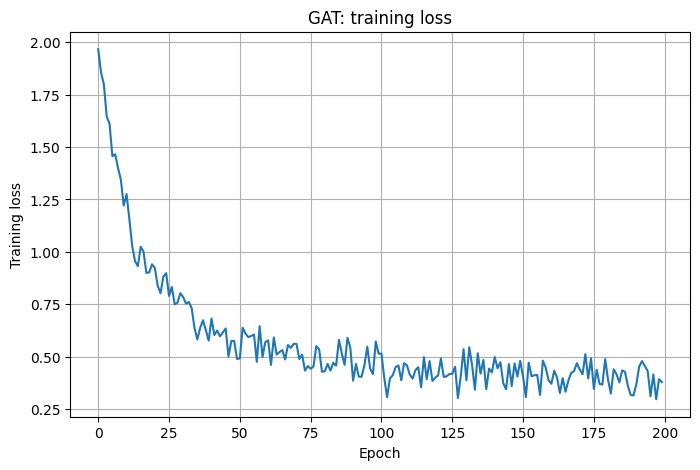

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("GAT: training loss")
plt.grid(True)
plt.show()

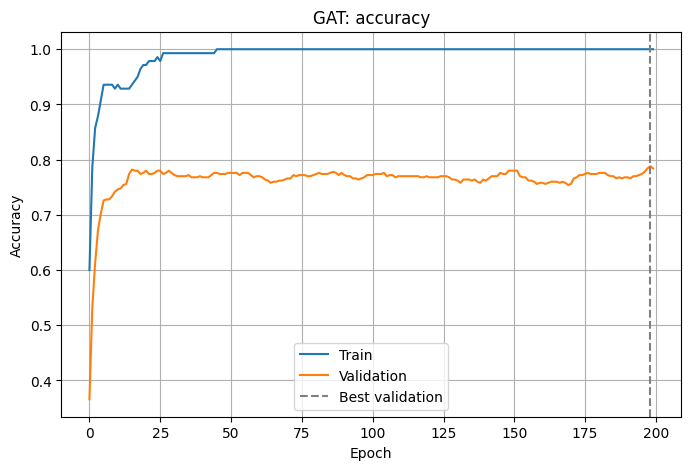

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="Best validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GAT: accuracy")
plt.legend()
plt.grid(True)
plt.show()

Unlike Tutorials 4 and 5, training accuracy climbs more gradually and the loss stays well above zero. Heavy dropout makes memorising the 140 labelled nodes harder, which is exactly its purpose. Exact curves vary with random initialisation and software versions.

# Part VI — Final test evaluation

## 20. Evaluate the best checkpoint on the test nodes

We load the weights from the best validation epoch and evaluate on the test set **once**.

In [20]:
model.load_state_dict(best_state)

test_acc = accuracy(model, data, data.test_mask)
print(f"Validation accuracy (best checkpoint): {accuracy(model, data, data.val_mask):.4f}")
print(f"Test accuracy:                         {test_acc:.4f}")

Validation accuracy (best checkpoint): 0.7880
Test accuracy:                         0.7880


We now have a complete GAT pipeline:

$$
\text{Graph}\rightarrow\underbrace{\mathbf W\mathbf h\rightarrow e_{ij}\rightarrow\alpha_{ij}\rightarrow\textstyle\sum_j\alpha_{ij}\mathbf z_j}_{\text{GAT layer}}\rightarrow\text{Logits}\rightarrow\text{Masked loss}\rightarrow\text{Backpropagation}
$$

The test accuracy is in the same range as GCN (Tutorial 4) and our message-passing layer (Tutorial 5). On Cora, learned attention gives at most a small improvement, and results vary by one or two percentage points between runs. We will look at why in the next part.

# Part VII — What happens inside a GAT?

## 21. Attention weights for one node

Let's look at the trained first layer. We pick a test node and print the attention it gives to each incoming edge (including itself), for the first head.

In [21]:
model.eval()
with torch.no_grad():
    _, (att_edge_index, att_weights) = model.conv1(
        data.x, data.edge_index, return_attention_weights=True
    )

print("Edges incl. self-loops:", att_edge_index.size(1))
print("Attention shape [edges, heads]:", tuple(att_weights.shape))

node_id = int(data.test_mask.nonzero()[0])
incoming = att_edge_index[1] == node_id
sources = att_edge_index[0, incoming]

print(f"\nNode {node_id} (label {data.y[node_id].item()}), head 0:")
for s, a in zip(sources.tolist(), att_weights[incoming, 0].tolist()):
    tag = "self" if s == node_id else f"label {data.y[s].item()}"
    print(f"  from {s:4d} ({tag:7s}): alpha = {a:.3f}")
print("  sum:", round(att_weights[incoming, 0].sum().item(), 4))

Edges incl. self-loops: 13264
Attention shape [edges, heads]: (13264, 8)

Node 1708 (label 3), head 0:
  from  467 (label 0): alpha = 0.148
  from  873 (label 0): alpha = 0.150
  from 1358 (label 2): alpha = 0.112
  from 1857 (label 3): alpha = 0.138
  from 2313 (label 2): alpha = 0.112
  from 2314 (label 3): alpha = 0.124
  from 1708 (self   ): alpha = 0.217
  sum: 1.0


## 22. Is attention actually different from averaging?

If attention were uniform, a node with $d$ incoming edges would give each one weight $1/d$, the mean aggregation from Tutorial 5. We can measure how far attention is from uniform with the **entropy** of each node's coefficients:

$$
H_i=-\sum_j\alpha_{ij}\log\alpha_{ij}
$$

Uniform attention has the maximum entropy $\log d_i$. Low entropy means the node focuses on a few neighbours.

In [22]:
dst = att_edge_index[1]
N = data.num_nodes
alpha_all = att_weights.mean(dim=1)   # average over heads

entropy = torch.zeros(N, device=dst.device).index_add_(
    0, dst, -alpha_all * alpha_all.clamp_min(1e-16).log()
)
degree = torch.zeros(N, device=dst.device).index_add_(
    0, dst, torch.ones_like(alpha_all)
)
uniform_entropy = degree.log()

has_choice = degree > 1
ratio = entropy[has_choice] / uniform_entropy[has_choice]
print(f"Nodes with more than one incoming edge: {int(has_choice.sum())}")
print(f"Mean entropy / uniform entropy: {ratio.mean():.3f}")
print("(1.0 = attention identical to averaging)")

Nodes with more than one incoming edge: 2708
Mean entropy / uniform entropy: 0.998
(1.0 = attention identical to averaging)


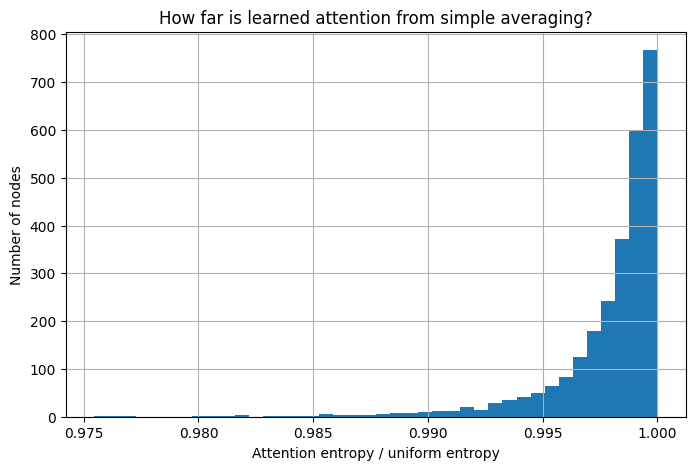

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(ratio.cpu().numpy(), bins=40)
plt.xlabel("Attention entropy / uniform entropy")
plt.ylabel("Number of nodes")
plt.title("How far is learned attention from simple averaging?")
plt.grid(True)
plt.show()

On Cora, most nodes give **nearly uniform** attention to their neighbours. This is a well-known observation: in Cora, connected papers usually share the same topic, so treating neighbours equally already works well, and attention has little to fix.

Attention helps more when neighbourhoods are **mixed**, when some neighbours are informative and others are noise. This is why GAT does not automatically beat GCN, and why careful comparisons matter.

## 23. GCN, mean aggregation, and GAT as message passing

We can now place all three layers in the Tutorial 5 framework:

| Step | Mean aggregation (T5) | GCN (T2–T4) | GAT (T6) |
|---|---|---|---|
| Message | $\mathbf h_j$ | $\dfrac{1}{\sqrt{\hat d_i\hat d_j}}\,\mathbf W\mathbf h_j$ | $\alpha_{ij}\,\mathbf W\mathbf h_j$ |
| Weight depends on | degree of $i$ | degrees of $i$ and $j$ | **features** of $i$ and $j$ |
| Aggregate | mean | sum (with self-loop) | sum (with self-loop) |
| Update | $\mathbf W[\mathbf h_i\Vert\mathbf m_i]+\mathbf b$ | add bias | concat/average heads, add bias |
| Extra parameters | — | — | $\mathbf a$ (2C per head) |

$$
\boxed{\text{GAT}=\text{GCN with learned, feature-dependent edge weights}}
$$

# Part VIII — Inspect predictions

## 24. Compare predicted and true labels on test nodes

In [24]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

probabilities = torch.softmax(logits, dim=1)
predictions = logits.argmax(dim=1)
test_ids = data.test_mask.nonzero(as_tuple=False).view(-1)[:15]

print("Node | True | Predicted | Confidence")
print("-------------------------------------")
for i in test_ids.tolist():
    pred = predictions[i].item()
    print(f"{i:4d} | {data.y[i].item():4d} | {pred:9d} | {probabilities[i, pred].item():10.3f}")

Node | True | Predicted | Confidence
-------------------------------------
1708 |    3 |         1 |      0.581
1709 |    2 |         2 |      0.992
1710 |    2 |         2 |      0.597
1711 |    2 |         2 |      0.998
1712 |    2 |         2 |      0.993
1713 |    0 |         0 |      0.651
1714 |    2 |         2 |      0.998
1715 |    2 |         2 |      0.999
1716 |    2 |         2 |      0.996
1717 |    2 |         2 |      0.994
1718 |    2 |         2 |      0.991
1719 |    2 |         2 |      0.996
1720 |    2 |         2 |      0.996
1721 |    2 |         2 |      0.998
1722 |    2 |         2 |      0.959


## 25. Are low-confidence predictions more often wrong?

In [25]:
test_mask = data.test_mask
confidence = probabilities.max(dim=1).values[test_mask]
correct = (predictions[test_mask] == data.y[test_mask])

threshold = 0.9
high = confidence >= threshold
print(f"Test nodes with confidence >= {threshold}: {int(high.sum())}, accuracy = {correct[high].float().mean():.3f}")
print(f"Test nodes with confidence <  {threshold}: {int((~high).sum())}, accuracy = {correct[~high].float().mean():.3f}")

Test nodes with confidence >= 0.9: 605, accuracy = 0.932
Test nodes with confidence <  0.9: 395, accuracy = 0.567


Compare these numbers with Tutorial 5. As before, confident predictions are much more reliable than uncertain ones, so the confidence score is still a useful signal even though it is not a calibrated probability.

# 🧪 Hands-on Exercise 5 — Number of heads

Train with 1, 2, 4, and 8 heads, keeping 8 features per head. For each, record the best validation accuracy, test accuracy, parameter count, and training time.

Questions:
1. Do more heads always help?
2. How does the parameter count grow with the number of heads?

In [30]:
# TODO: vary the number of attention heads.

# for heads in [1, 2, 4, 8]:
#     model = GAT(dataset.num_node_features, 8, dataset.num_classes, heads=heads).to(device)
#     ...

# 🧪 Hands-on Exercise 6 — Dropout

Try `dropout=0.0`, `0.3`, and `0.6`. Compare the training and validation curves.

Why might a GAT need stronger regularisation than the GCN in Tutorial 4? (Hint: compare parameter counts, and think about what the attention coefficients can fit with only 140 labels.)

In [31]:
# TODO: rebuild the model with different dropout values and retrain.

# dropout_probability = 0.0
# model = GAT(dataset.num_node_features, 8, dataset.num_classes, heads=8,
#             dropout=dropout_probability).to(device)

# 🧪 Hands-on Exercise 7 — Use our own layer

Replace `GATConv` in the `GAT` model with our `PyGGATConv` and train it on Cora.

Hint: `PyGGATConv` has no attention dropout. Does that change the result? Try adding `F.dropout` to `alpha` inside `message()`.

In [32]:
# TODO: build a GAT model from PyGGATConv.

# class OurGAT(nn.Module):
#     def __init__(self, input_dim, hidden_dim, output_dim, heads=8, dropout=0.6):
#         super().__init__()
#         self.conv1 = PyGGATConv(input_dim, hidden_dim, heads=heads, concat=True)
#         self.conv2 = PyGGATConv(hidden_dim * heads, output_dim, heads=1, concat=False)
#         self.dropout = dropout
#
#     def forward(self, x, edge_index):
#         ...

# 🧪 Hands-on Exercise 8 — Compare attention heads on Cora

For the node from Section 21, print the attention coefficients of **all 8 heads** side by side. Do the heads focus on the same neighbours? Compute the entropy ratio from Section 22 per head instead of averaging over heads.

In [33]:
# TODO: compare the 8 heads for one node.

# print(att_weights[incoming])   # rows: incoming edges, columns: heads

# Part IX — Interpreting attention, and attention on meshes

## 26. Be careful when interpreting attention

Attention weights are easy to plot, which makes them tempting to read as explanations. Keep in mind:

1. **Attention is local.** Coefficients are normalised within one destination's neighbourhood. A weight of 0.5 at a node with 2 neighbours and 0.5 at a node with 20 neighbours mean very different things.
2. **Attention is not causal importance.** A large $\alpha_{ij}$ shows how a layer weighted a message, not that the neighbour caused the prediction.
3. **Heads and layers differ.** Each head and each layer has its own coefficients; there is no single "attention map".
4. **Attention does not use edge features** in the basic formulation. If distances or edge types matter, the score function must be extended (e.g. `GATConv(..., edge_dim=...)`).
5. **Cost grows with heads and degree.** One score is computed per edge, per head.

## 27. Attention on computational meshes

| Graph concept | Possible mesh interpretation |
|---|---|
| Node | cell centre, mesh vertex, or control volume |
| Edge | cell adjacency or shared face |
| Node features | pressure, velocity, temperature |
| Edge features | distance, face normal, face area |
| Attention $\alpha_{ij}$ | learned weight of neighbour $j$ for cell $i$ |

In a finite-volume method, neighbour weights are fixed by geometry (face areas, distances). A GAT instead learns weights from the **field values**. This can help capture features like shocks or boundary layers, where some neighbours are more informative than others.

However, a standard GAT is not a finite-volume scheme:
- $\alpha_{ij}$ is not a face flux, and $\alpha_{ij}\neq\alpha_{ji}$ in general, so conservation is not guaranteed.
- The softmax ignores geometry unless edge features are added to the score.

For engineering problems, a good starting point is to include relative position and distance as edge features and compare against geometry-based message passing. We will return to this in Tutorials 9 and 10.

# 🚀 Final Challenge — A controlled GCN vs. GAT comparison

Build a small, fair experimental study on Cora:

1. Train the GCN from Tutorial 4.
2. Train the message-passing layer from Tutorial 5.
3. Train a GAT with 1 head.
4. Train a GAT with 8 heads.

Rules for a fair comparison:
- Use the same train/validation/test masks for every model.
- Select the checkpoint by validation accuracy, then evaluate the test set once.
- Repeat each model with **5 random seeds** and report mean ± standard deviation.

| Model | Heads | Parameters | Val accuracy | Test accuracy (mean ± std) | Time / epoch |
|---|---:|---:|---:|---:|---:|
| GCN (T4) | — | ? | ? | ? | ? |
| Message passing (T5) | — | ? | ? | ? | ? |
| GAT | 1 | ? | ? | ? | ? |
| GAT | 8 | ? | ? | ? | ? |

Do not assume GAT must win. Explain your results using the entropy analysis from Section 22: if attention is nearly uniform on Cora, what would you expect?

### Completion checklist

- [ ] I can explain the four steps of a GAT layer.
- [ ] I understand why the softmax is computed per destination node.
- [ ] I implemented a GAT layer from scratch with `index_add_`.
- [ ] I understand concatenating vs. averaging attention heads.
- [ ] I wrote GAT as a PyG `MessagePassing` layer and verified it against `GATConv`.
- [ ] I trained and evaluated a GAT on Cora.
- [ ] I can explain why attention weights are not automatically explanations.

# 28. Summary

We learned:
- why equal or degree-based neighbour weights can be limiting
- how a GAT scores each edge with a learned attention vector
- how a destination-wise softmax turns scores into coefficients that sum to one
- how to implement a GAT layer from scratch and with PyG's `MessagePassing`
- how multi-head attention works, and when to concatenate or average heads
- how to train a GAT on Cora with the Tutorial 4–5 workflow
- that attention on Cora is close to uniform, which explains why GAT and GCN perform similarly there
- why attention weights must be interpreted carefully

The key takeaway:

> The graph decides **which** neighbours can send messages. Attention learns **how much** each message counts.

# 29. What comes next?

## Tutorial 7 — GraphSAGE and Advanced Aggregation

So far, every layer has processed the **whole graph** in each forward pass. That works for Cora's 2,708 nodes, but not for graphs with millions of nodes and edges.

In the next tutorial, we look at how GraphSAGE scales:

```text
Pick a batch of target nodes
    ↓
Sample a fixed number of neighbours per hop
    ↓
Message passing on the sampled subgraph
    ↓
Update only the target nodes
```

We will also compare richer aggregation functions — mean, max, sum, and learnable aggregators — building directly on Tutorial 5.

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**